## Contenuti
- [Import delle librerie](#Import-delle-librerie)
- [Definizione del training set e del pattern di test](#Definizione-del-training-set-e-del-pattern-di-test)
- [Calcolo del vettore medio](#Calcolo-del-vettore-medio)
- [Calcolo della matrice di covarianza](#Calcolo-della-matrice-di-covarianza)
- [Calcolo della densità di probabilità condizionale](#Calcolo-della-densità-di-probabilità-condizionale)
- [Probabilità a posteriori](#Probabilità-a-posteriori)
    - [Probabilità a priori](#Probabilità-a-priori)
    - [Densità di probabilità assoluta](#Densità-di-probabilita-assoluta)
- [Visualizzazione dei risultati](#Visualizzazione-dei-risultati)

# Esercitazione 2
Nella lezione odierna riguarda l'implementazione di un classificatore Bayesiano binario.

Come problema di riferimento si chiede di implementare un **classificatore di Bayes parametrico** (multinormale) per stimare il genere di un individuo con peso e altezza rispettivamente pari a 57kg e 168cm.


## Import delle librerie
Il primo passo consiste nell'eseguire l'import delle librerie utilizzate.

Oltre alle librerie Numpy e Matplotlib, si dovranno importare due ulteriori librerie che verranno utilizzate per la visualizzazione dei risultati (**itertools**, **ml_visualization**).

In [1]:
import matplotlib.pyplot as plt  # Matplotlib, per la visualizzazione dei risultati
import matplotlib  # Import del package principale, contenente costanti utili
import numpy as np  # Numpy
import itertools

import ml_visualization

## Definizione del training set e del pattern di test
I dati riportati in tabella rappresentano il training set con cui verrà addestrato il classificatore (le classi *Maschio* e *Femmina* sono qui denominate rispettivamente *W1* e *W2*).
<img src="Tabella_trainingset.png" alt="Tabella training set" style="width: 250px;"/>

Di seguito la definizione del training set e del pattern di test e la relativa visualizzazione su un piano cartesiano.

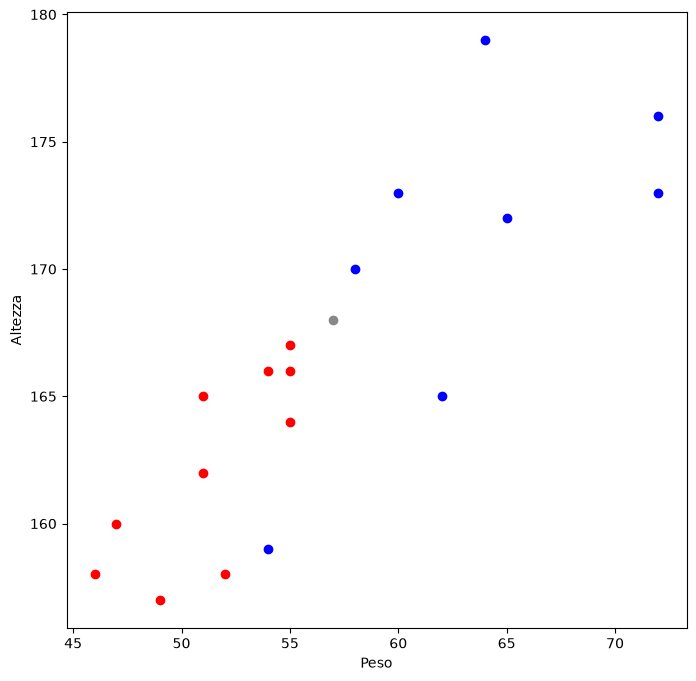

In [2]:
# Definizione del training set
patterns_W1 = np.array([[72, 173], [54, 159], [65, 172], [58, 170],
                        [62, 165], [72, 176], [60, 173], [64, 179]])
patterns_W2 = np.array([[55, 166], [46, 158], [52, 158], [47, 160], [55, 167],
                        [54, 166], [55, 164], [49, 157], [51, 165], [51, 162]])

# Definizione del pattern di test
X = np.array([57, 168])

# Visualizzazione dei dati. Il pattern di test è visualizzato in grigio
plt.scatter(patterns_W1[:, 0], patterns_W1[:, 1], c='#0000FF')
plt.scatter(patterns_W2[:, 0], patterns_W2[:, 1], c='#FF0000')
plt.scatter(X[0], X[1], c='#888888')
plt.xlabel('Peso')
plt.ylabel('Altezza')
plt.show()

# Calcolo del numero di pattern per le due classi
pattern_count_W1 = patterns_W1.shape[0]
pattern_count_W2 = patterns_W2.shape[0]

## Calcolo del vettore medio
Si completi la funzione **compute_mean(...)** senza utilizzare la funzione **mean(...)** di Numpy. Questa deve restituire il vettore medio di un insieme di pattern di input.

Il vettore medio è dato da:

$\Large{\boldsymbol{\mu}=\frac{1}{n}\sum_{i=1..n}\boldsymbol{x}_i}$

In [3]:
# Esercizio 1: implementare il calcolo dei vettori medi
def compute_mean(patterns):
    n = patterns.shape[0]
    return np.sum(patterns, axis=0) / n

# Calcolo dei vettori medi
mu_W1 = compute_mean(patterns_W1)
mu_W2 = compute_mean(patterns_W2)

print('Vettore medio mu1:', mu_W1)
print('Vettore medio mu2:', mu_W2)

Vettore medio mu1: [ 63.375 170.875]
Vettore medio mu2: [ 51.5 162.3]


## Calcolo della matrice di covarianza
Si completi la funzione **compute_covariance_matrix(...)** senza utilizzare la funzione **cov(...)** di Numpy. Questa deve restituire la matrice di covarianza di un insieme di pattern di input dato il vettore medio.

La matrice di covarianza è data da:

$\Large{\boldsymbol{\Sigma}=\frac{1}{n}\sum_{i=1..n}(\boldsymbol{x}_i-\boldsymbol{\mu})(\boldsymbol{x}_i-\boldsymbol{\mu})^t}$

In [4]:
# Esercizio 2: implementare il calcolo delle matrici di covarianza
def compute_covariance_matrix(patterns, mean):
    n = patterns.shape[0]
    X = patterns - mean
    return (X.T @ X) / n


# Calcolo delle matrici di covarianza
cov_mat_W1 = compute_covariance_matrix(patterns_W1, mu_W1)
cov_mat_W2 = compute_covariance_matrix(patterns_W2, mu_W2)

print('Matrice di covarianza per W1:\n', cov_mat_W1)
print('\nMatrice di covarianza per W2:\n', cov_mat_W2)

Matrice di covarianza per W1:
 [[35.234375 23.296875]
 [23.296875 34.859375]]

Matrice di covarianza per W2:
 [[10.05  8.85]
 [ 8.85 13.01]]


## Calcolo della densità di probabilità condizionale
Prima di poter calcolare la densità di probabilità condizionale è necessario calcolare la matrice inversa e il determinante delle due matrici di covarianza.

In [5]:
# Determinanti delle matrici di covarianza
det_cov_mat_W1 = np.linalg.det(cov_mat_W1)
det_cov_mat_W2 = np.linalg.det(cov_mat_W2)
print('Determinante cov_mat_W1:', det_cov_mat_W1)
print('Determinante cov_mat_W2:', det_cov_mat_W2)

# Inverse delle matrici di covarianza
inv_cov_mat_W1 = np.linalg.inv(cov_mat_W1)
inv_cov_mat_W2 = np.linalg.inv(cov_mat_W2)
print('Inversa cov_mat_W1:\n', inv_cov_mat_W1)
print('\nInversa cov_mat_W2:\n', inv_cov_mat_W2)

Determinante cov_mat_W1: 685.5039062500001
Determinante cov_mat_W2: 52.42800000000001
Inversa cov_mat_W1:
 [[ 0.05085219 -0.03398504]
 [-0.03398504  0.05139923]]

Inversa cov_mat_W2:
 [[ 0.24814984 -0.16880293]
 [-0.16880293  0.19169146]]


In [6]:
# Esercizio 3: implementare il calcolo delle densità di probabilità condizionali
def compute_density(x, mean, inv_cov_matrix, det):
    d = x.shape[0]
    diff = x - mean
    norm = 1 / ((2 * np.pi) ** (d / 2) * np.sqrt(det))
    exponent = -0.5 * (diff.T @ inv_cov_matrix @ diff)
    return norm * np.exp(exponent)
    
# Densità di probabilità condizionali
p_X_W1 = compute_density(X, mu_W1, inv_cov_mat_W1, det_cov_mat_W1)
p_X_W2 = compute_density(X, mu_W2, inv_cov_mat_W2, det_cov_mat_W2)

print('Densità di probabilità condizionale p(X|w1) = ', p_X_W1)
print('Densità di probabilità condizionale p(X|w2) = ', p_X_W2)

Densità di probabilità condizionale p(X|w1) =  0.0032606524569577305
Densità di probabilità condizionale p(X|w2) =  0.004548672653313878


Si implementi la funzione **compute_density(...)** che calcoli la densità di probabilità condizionale di un pattern $\textit{x}$ dati il vettore medio *mean*, l'inversa della matrice di covarianza *inv_cov_matrix* e il determinante *det*.

La formula per il calcolo della densità di probabilità condizionale è:


$\Large{p(\boldsymbol{x}|w_i)=\frac{1}{(2π)^{d/2} |\boldsymbol{\Sigma}_i|^{1/2}}e^{-\frac{1}{2}(\boldsymbol{x}-\boldsymbol{\mu}_i)^t \boldsymbol{\Sigma}_i^{-1} (\boldsymbol{x}-\boldsymbol{\mu}_i)}}$

## Probabilità a posteriori
Prima di porter calcolare la probabilità a posteriori $\large{P(w_{i} | \boldsymbol{x})}$ è necessario stimare:
- la probabilità a priori;
- la densità di probabilità assoluta.

### Probabilità a priori
La probabilità a priori può essere stimata utilizzando la formula seguente:

$\large{P(w_i)=\frac{|w_i |}{|W|}}$ 

In [7]:
# Probabilità a priori
all_patterns_count = pattern_count_W1 + pattern_count_W2
p_W1 = pattern_count_W1 / all_patterns_count
p_W2 = pattern_count_W2 / all_patterns_count

print('Probabilità a priori p(w1) = ', p_W1)
print('Probabilità a priori p(w2) = ', p_W2)

Probabilità a priori p(w1) =  0.4444444444444444
Probabilità a priori p(w2) =  0.5555555555555556


### Densità di probabilità assoluta
La densità di probabilità assoluta può essere calcolata come:

$\Large{p(\boldsymbol{x})=\sum_{i=1}^s p(\boldsymbol{x}|w_i)P(w_i)}$

In [8]:
# Densità di probabilità assoluta
p_x = p_X_W1 * p_W1 + p_X_W2 * p_W2
print('Densità di probabilità assoluta p(X) = ', p_x)

Densità di probabilità assoluta p(X) =  0.003976219232711146


Infine la probabilità a posteriori può essere stimata come: 

$\Large{P(w_i|\boldsymbol{x})=\frac{p(\boldsymbol{x}|w_i )P(w_i )}{p(\boldsymbol{x})}}$

In [9]:
# Probabilità a posteriori
p_W1_X = p_X_W1 * p_W1 / p_x
p_W2_X = p_X_W2 * p_W2 / p_x

print('Probabilità a posteriori p(w1|X) = ', p_W1_X)
print('Probabilità a posteriori p(w2|X) = ', p_W2_X)

Probabilità a posteriori p(w1|X) =  0.3644615110346627
Probabilità a posteriori p(w2|X) =  0.6355384889653373


Il pattern di test è assegnato alla classe *b* per cui è massima la probabilità a posteriori:

$\Large{b=\underset{i=1..s}{\arg\max}\{P(w_i|\boldsymbol{x})\}}$

In questo caso il pattern è assegnato alla classe *W2 (Femmine)*, essendo $\large{P(w_2|\boldsymbol{x}) > P(w_1|\boldsymbol{x})}$.

## Visualizzazione dei risultati
Di seguito è proposta una rappresentazione grafica dei risultati ottenuti. Il codice crea un piano cartesiano in cui sono visualizzati:
1. I pattern del training set, di colore blu per i "Maschi" e di colore rosso per le "Femmine";
2. Il pattern di test, di colore grigio;
3. Uno sfondo che rappresenta la probabilità a posteriori nelle diverse parti del piano.

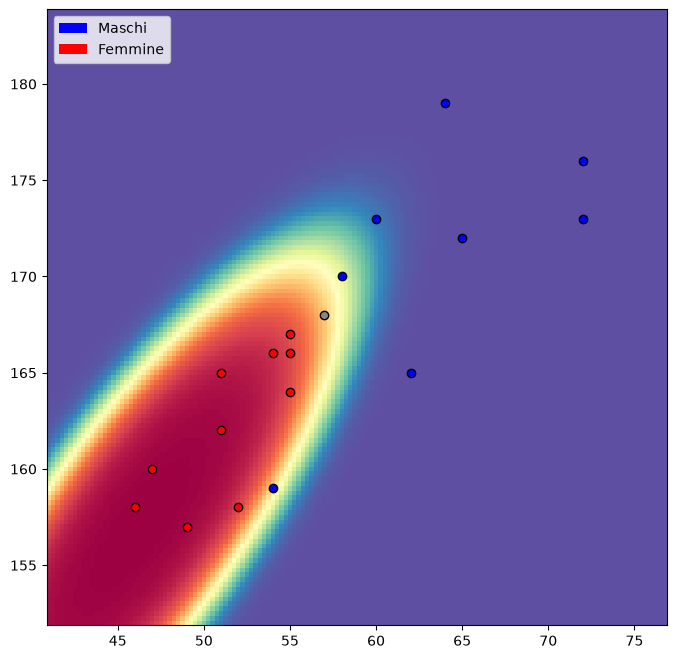

In [12]:
def calculate_probability_map(means, inv_covariance_matrices, det_cov_matrices, prior_probabilities,
                              x_min, x_max, y_min, y_max, step):
    x_range = np.arange(x_min, x_max, step)
    y_range = np.arange(y_min, y_max, step)

    probability_map = np.zeros((y_range.shape[0], x_range.shape[0]))

    for i, j in itertools.product(range(y_range.shape[0]), range(x_range.shape[0])):
        p = np.array([x_range[j], y_range[i]])
        densities = np.array(
            [compute_density(p, means[i], inv_covariance_matrices[i], det_cov_matrices[i]) for i in range(len(means))])
        px = (densities * prior_probabilities).sum()
        probabilities = np.array([densities[i] * prior_probabilities[i] / px for i in range(0, len(means))])
        probability_map[i, j] = probabilities[0]

    return probability_map, x_range, y_range


# Calcolo delle aree di probabilità
x_min, x_max, y_min, y_max = ml_visualization.calculate_2D_min_max(np.concatenate((patterns_W1, patterns_W2)), 5)
probability_map, x_range, y_range = calculate_probability_map(np.array([mu_W1, mu_W2]),
                                                            np.array([inv_cov_mat_W1, inv_cov_mat_W2]),
                                                            np.array([det_cov_mat_W1, det_cov_mat_W2]),
                                                            np.array([p_W1, p_W2]),
                                                            x_min, x_max, y_min, y_max, 0.25)

# Disegno delle aree di probabilità
colors = ml_visualization.get_colors_from_colormap(plt.cm.RdBu, 0.001)
ml_visualization.decisionboundaries_drawing(0, x_range, y_range, probability_map, matplotlib.colors.ListedColormap(colors))

# Plotting dei patterns
ml_visualization.plotting_patterns(0, patterns_W1, '#0000FF', 36)
ml_visualization.plotting_patterns(0, patterns_W2, '#FF0000', 36)
ml_visualization.plotting_patterns(0, np.array([X]), '#888888', 36)

# Disegno della legenda
colors = ['#0000FF', '#FF0000']
labels = ['Maschi', 'Femmine']
ml_visualization.legend_drawing(0, colors, labels, 2)

plt.show()